<a href="https://colab.research.google.com/github/Mohtasim4458/Artificial-Intelligence/blob/main/AI_Assignment_Python_Basics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

TASK 1
Solution length: 14
Nodes expanded: 5961
Nodes generated: 9021
Time: 0.010015 seconds

TASK 2: SOLUTION
Move 0:
8 1 3
4 _ 2
7 6 5

Move 1:
8 1 3
4 2 _
7 6 5

Move 2:
8 1 3
4 2 5
7 6 _

Move 3:
8 1 3
4 2 5
7 _ 6

Move 4:
8 1 3
4 2 5
_ 7 6

Move 5:
8 1 3
_ 2 5
4 7 6

Move 6:
_ 1 3
8 2 5
4 7 6

Move 7:
1 _ 3
8 2 5
4 7 6

Move 8:
1 2 3
8 _ 5
4 7 6

Move 9:
1 2 3
_ 8 5
4 7 6

Move 10:
1 2 3
4 8 5
_ 7 6

Move 11:
1 2 3
4 8 5
7 _ 6

Move 12:
1 2 3
4 _ 5
7 8 6

Move 13:
1 2 3
4 5 _
7 8 6

Move 14:
1 2 3
4 5 6
7 8 _


TASK 3: RANDOM STATES
Scramble Moves | Solution Depth | Nodes Expanded
             5 |              5 |             52
Start state: (1, 5, 2, 4, 3, 0, 7, 8, 6)
            10 |             10 |            897
Start state: (4, 1, 3, 7, 0, 2, 5, 8, 6)
            15 |             15 |           6968
Start state: (1, 2, 5, 7, 3, 6, 4, 0, 8)
            20 |             14 |           3378
Start state: (4, 5, 0, 7, 2, 1, 8, 6, 3)
            25 |             23 |         10667

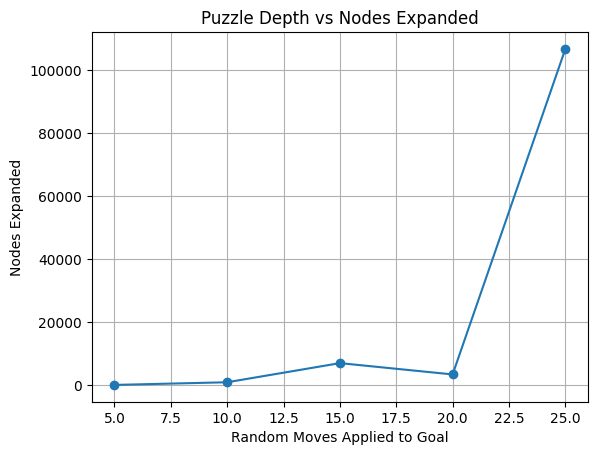


Comment: BFS explores nodes level by level.
As solution depth increases, nodes expanded can grow rapidly.
Random states may have shorter solutions than their scramble length.

TASK 4: UNSOLVABLE STATE
Start state: (1, 2, 3, 4, 5, 6, 8, 7, 0)
Unsolvable state. Search was not started.
Nodes expanded: 0
Nodes generated: 0


In [3]:
from collections import deque
import random
import time
import matplotlib.pyplot as plt

GOAL = (1, 2, 3, 4, 5, 6, 7, 8, 0)


def is_solvable(state):
    tiles = [x for x in state if x != 0]
    inversions = sum(
        tiles[i] > tiles[j]
        for i in range(len(tiles))
        for j in range(i + 1, len(tiles))
    )
    return inversions % 2 == 0


def get_neighbors(state):
    zero = state.index(0)
    row, col = divmod(zero, 3)
    moves = []

    if row > 0:
        moves.append(zero - 3)
    if row < 2:
        moves.append(zero + 3)
    if col > 0:
        moves.append(zero - 1)
    if col < 2:
        moves.append(zero + 1)

    neighbors = []
    for pos in moves:
        new_state = list(state)
        new_state[zero], new_state[pos] = new_state[pos], new_state[zero]
        neighbors.append(tuple(new_state))

    return neighbors


def solve_puzzle(start):
    if not is_solvable(start):
        print("Unsolvable state. Search was not started.")
        return None, 0, 0, 0, 0

    start_time = time.perf_counter()
    queue = deque([start])
    parent = {start: None}
    nodes_expanded = 0

    while queue:
        current = queue.popleft()
        nodes_expanded += 1

        if current == GOAL:
            break

        for neighbor in get_neighbors(current):
            if neighbor not in parent:
                parent[neighbor] = current
                queue.append(neighbor)

    elapsed = time.perf_counter() - start_time

    path = []
    current = GOAL

    while current is not None:
        path.append(current)
        current = parent[current]

    path.reverse()

    solution_length = len(path) - 1
    nodes_generated = len(parent)

    return path, solution_length, nodes_expanded, nodes_generated, elapsed


def print_board(state):
    for i in range(0, 9, 3):
        print(" ".join("_" if x == 0 else str(x)
                       for x in state[i:i + 3]))
    print()


# Task 2: Print the board after every move
def print_solution(start, path):
    if path is None:
        return

    for move, state in enumerate(path):
        print(f"Move {move}:")
        print_board(state)


# Task 1: Solve the given start state
start = (8, 1, 3, 4, 0, 2, 7, 6, 5)

print("TASK 1")
path, length, expanded, generated, elapsed = solve_puzzle(start)

if path is not None:
    print("Solution length:", length)
    print("Nodes expanded:", expanded)
    print("Nodes generated:", generated)
    print("Time:", round(elapsed, 6), "seconds")

    print("\nTASK 2: SOLUTION")
    print_solution(start, path)


# Task 3: Generate random solvable states
def random_state(moves):
    state = GOAL
    previous = None

    for _ in range(moves):
        choices = get_neighbors(state)

        if previous is not None and len(choices) > 1:
            choices = [s for s in choices if s != previous]

        next_state = random.choice(choices)
        previous, state = state, next_state

    return state


print("\nTASK 3: RANDOM STATES")
depths = [5, 10, 15, 20, 25]
expanded_nodes = []

print("Scramble Moves | Solution Depth | Nodes Expanded")

for depth in depths:
    state = random_state(depth)
    path, length, expanded, generated, elapsed = solve_puzzle(state)

    expanded_nodes.append(expanded)

    print(f"{depth:14} | {length:14} | {expanded:14}")
    print("Start state:", state)

plt.plot(depths, expanded_nodes, marker="o")
plt.xlabel("Random Moves Applied to Goal")
plt.ylabel("Nodes Expanded")
plt.title("Puzzle Depth vs Nodes Expanded")
plt.grid(True)
plt.show()

print("\nComment: BFS explores nodes level by level.")
print("As solution depth increases, nodes expanded can grow rapidly.")
print("Random states may have shorter solutions than their scramble length.")


# Task 4: Test an unsolvable state
print("\nTASK 4: UNSOLVABLE STATE")

unsolvable = (1, 2, 3, 4, 5, 6, 8, 7, 0)

print("Start state:", unsolvable)
path, length, expanded, generated, elapsed = solve_puzzle(unsolvable)

print("Nodes expanded:", expanded)
print("Nodes generated:", generated)